Predict which chargers are most likely to need maintenance, using each charger's utilisation, session duration, and energy patterns. The dataset records no faults or downtime, so a real failure label does not exist. The notebook builds a charger health indicator from session behaviour, tests whether a model can predict a proxy for trouble (a long idle spell, and ranks chargers for maintenance attention.  
Definitions used throughout:
* **Health indicator:** a measure of how a charger behaves, built from its sessions (for example utilisation or delivered power).
* **Utilisation:** the share of a charger's available time that it is in use, with overlapping sessions merged. Available time runs from 1 January of the station's activation year to the end of 2024.
* **Power ratio:** the average power delivered during a session divided by the charger's power.
* **Inactivity event (proxy for failure):** a charger goes 3 or more days without starting a session. This can't distinguish a fault from a quiet charger, so it's only a proxy.
* **Wear:** how much work a charger has done, measured by cumulative energy delivered and hours in use.
* **AUC:** how well a model ranks risky cases above safe ones, from  (no better than chance) to 1 (perfect).

**Set up**  
Libraries are imported, and the input path is set. show() saves every chart as a PNG in a figures folder (for the repo) and then displays it. 

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 50, 'axes.titlesize': 12, 'axes.labelsize': 10})

DATA_PATH = '/kaggle/input/datasets/sanyazuberi/ev-charging-raw-dataset/Copy of ev_charging_dataset.xlsx'
OUT = '/kaggle/working'
FIG_DIR = f'{OUT}/figures'
os.makedirs(FIG_DIR, exist_ok=True)

def show(name):
    """Save the current figure as a PNG (for the repo) and display it."""
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=100, bbox_inches='tight')
    plt.show()

**Loading the data**  
All three sheets are needed: stations (activation year and size), chargers (type and rated power), and sessions (what each charger did). 

In [2]:
stations = pd.read_excel(DATA_PATH, sheet_name='stations')
chargers = pd.read_excel(DATA_PATH, sheet_name='chargers')
sessions = pd.read_excel(DATA_PATH, sheet_name='sessions')

for c in ['start_timestamp', 'end_timestamp']:
    sessions[c] = pd.to_datetime(sessions[c])
chargers['installation_date'] = pd.to_datetime(chargers['installation_date'])

print(f"stations: {len(stations)} | chargers: {len(chargers)} | sessions: {len(sessions):,}")
print(chargers['charger_type'].value_counts().to_dict())

stations: 33 | chargers: 199 | sessions: 294,024
{'DC_50kW': 95, 'DC_150kW': 69, 'DC_300kW': 35}


The data has 33 stations, 199 chargers (95 rated 50 kW, 69 rated 150 kW, and 35 rated 300 kW), and 294,024 sessions. Sessions run from 1 January 2022 to 31 December 2024, and the last ones end just after midnight on 1 January 2025.

**Is there any failure or fault information?**  
Predictive maintenance needs a record of when chargers failed. I searched the column names for fault-related words, checked for missing values and duplicates, and tested the sessions for signs   of trouble: delivered power far below rated power, very short or very small sessions, sessions that overlap on the same charger, and long idle gaps.

In [3]:
fault_words = ['status', 'fault', 'error', 'outage', 'maint', 'downtime', 'alarm', 'fail', 'repair']
for name, df in [('stations', stations), ('chargers', chargers), ('sessions', sessions)]:
    hits = [c for c in df.columns if any(w in c.lower() for w in fault_words)]
    print(f"{name}: fault-related columns = {hits} | missing values = {int(df.isna().sum().sum())}")
print('Duplicate session ids:', sessions['session_id'].duplicated().sum())

s = sessions.merge(chargers[['charger_id', 'max_power_kW']], on='charger_id')
s['power_ratio'] = (s['energy_kwh'] / (s['session_duration_minutes'] / 60)) / s['max_power_kW']
print('Power ratio (min / median / max):', s['power_ratio'].agg(['min', 'median', 'max']).round(2).to_dict())
print('Shortest session (min):', s['session_duration_minutes'].min(), '| smallest session (kWh):', s['energy_kwh'].min())

s = s.sort_values(['charger_id', 'start_timestamp'])
s['prev_end'] = s.groupby('charger_id')['end_timestamp'].shift()
overlap = s['start_timestamp'] < s['prev_end']
print(f"Sessions starting before the previous one on the same charger has ended: {overlap.sum():,} ({overlap.mean():.1%})")

gap_days = (s['start_timestamp'] - s['prev_end']).dt.total_seconds() / 86400
longest_gap = gap_days.groupby(s['charger_id']).max()
print('Longest idle gap per charger, days (median / max):', round(longest_gap.median(), 1), '/', round(longest_gap.max(), 1))
print('Chargers with a gap over 7 days:', (longest_gap > 7).sum())

stations: fault-related columns = [] | missing values = 0
chargers: fault-related columns = [] | missing values = 0
sessions: fault-related columns = [] | missing values = 0
Duplicate session ids: 0
Power ratio (min / median / max): {'min': 0.64, 'median': 0.8, 'max': 0.9}
Shortest session (min): 15 | smallest session (kWh): 21.7
Sessions starting before the previous one on the same charger has ended: 24,425 (8.3%)
Longest idle gap per charger, days (median / max): 3.5 / 8.2
Chargers with a gap over 7 days: 3


None of the three sheets has a fault, status, outage, or maintenance column, and no values are missing or sessions are duplicated. No charger is recorded as having failed.  
The sessions show no signs of trouble. Delivered power is always 64% to 90% of rated power (median 80%), so nothing suggests derating or a faulty meter. Every session lasts at least 15 minutes and delivers at least 21.7 kWh, so no sessions are aborted. The longest idle gap for chargers is 8.2 days (median 3.5), and only 3 chargers ever go quiet for over a week.  
The one irregularity is that 24,425 sessions (8.3%) start before the previous session on the same charger has ended. This points to an allocation or logging problem, not a hardware fault. The count may differ slightly from your utilisation notebook because of how ties are handled. 

**What this means for the approach**  
With no failure records, a model cannot learn what a failing charger looks like, so it is set up as follows:  
* **Health indicators** are built from session behaviour, which is valid on its own.
* **The failure-risk model** predicts a proxy: an inactive event, meaning a charger starts no session for 3 or more days in the next month. This cannot separate a fault from a quiet charger, so it is reported as inactivity risk, not failure risk.
* **The priority list and recommendations** combine this risk with wear measures, and are meant to guide inspections until real fault logs can confirm them.

**Building the health indicators**  
One row per charger, built from its sessions. Overlapping sessions on a charger are merged before counting busy time, and available time runs from 1 January of the station's activation year to the end of 2024. Indicators cover usage (utilisation, sessions and energy per day), session shape (duration and its variability, energy per session), delivered power (power ratio), data quality (overlap rate), and quiet spells (the longest gap between session starts).

In [4]:
END = pd.Timestamp('2025-01-01')    # end of 2024

ch = chargers.merge(stations[['station_id', 'region', 'activation_year', 'n_chargers']], on='station_id').set_index('charger_id')
ch['avail_start'] = pd.to_datetime(ch['activation_year'].astype(str) + '-01-01')
ch['avail_days'] = (END - ch['avail_start']).dt.days

s = sessions.merge(chargers[['charger_id', 'max_power_kW']], on='charger_id')
s = s.sort_values(['charger_id', 'start_timestamp']).reset_index(drop=True)
s['power_ratio'] = (s['energy_kwh'] / (s['session_duration_minutes'] / 60)) / s['max_power_kW']

g = s.groupby('charger_id')
s['overlap'] = (s['start_timestamp'] < g['end_timestamp'].shift()).astype(int)
s['quiet_days'] = g['start_timestamp'].diff().dt.total_seconds() / 86400    # days since the previous session started

# busy minutes with overlapping sessions merged
prev_max_end = g['end_timestamp'].transform(lambda x: x.cummax().shift())
eff_start = s['start_timestamp'].where(prev_max_end.isna() | (s['start_timestamp'] >= prev_max_end), prev_max_end)
s['busy_min'] = ((s['end_timestamp'] - eff_start).dt.total_seconds() / 60).clip(lower=0)

g = s.groupby('charger_id')
ind = pd.DataFrame({
    'sessions'          : g.size(),
    'kwh_total'         : g['energy_kwh'].sum(),
    'busy_hours'        : g['busy_min'].sum() / 60,
    'avg_duration_min'  : g['session_duration_minutes'].mean(),
    'duration_cv'       : g['session_duration_minutes'].std() / g['session_duration_minutes'].mean(),
    'kwh_per_session'   : g['energy_kwh'].mean(),
    'power_ratio'       : g['power_ratio'].mean(),
    'overlap_rate'      : g['overlap'].mean(),
    'longest_quiet_days': g['quiet_days'].max(),
    'mean_quiet_days'   : g['quiet_days'].mean(),
})
ind = ch[['station_id', 'charger_type', 'max_power_kW', 'n_chargers', 'region', 'activation_year', 'avail_days']].join(ind)
ind['utilisation'] = ind['busy_hours'] * 60 / (ind['avail_days'] * 1440)
ind['sessions_per_day'] = ind['sessions'] / ind['avail_days']
ind['kwh_per_day'] = ind['kwh_total'] / ind['avail_days']
# longest quiet spell relative to what random session arrivals would typically give for this charger's traffic (1 = as expected)
ind['gap_ratio'] = ind['longest_quiet_days'] / (ind['mean_quiet_days'] * (np.log(ind['sessions']) + 0.577))
print(ind.shape)

(199, 21)


**Adding trend indicators**  
Two indicators compare the last 90 days of 2024 with the previous 12 months: the change in sessions per day and the change in power ratio. A falling session rate or falling delivered power would be an early sign of trouble. 

In [5]:
last90 = s['start_timestamp'] >= END - pd.Timedelta(days=90)
prior  = (s['start_timestamp'] < END - pd.Timedelta(days=90)) & (s['start_timestamp'] >= END - pd.Timedelta(days=455))
prior_start = ch['avail_start'].clip(lower=END - pd.Timedelta(days=455))
prior_days = (END - pd.Timedelta(days=90) - prior_start).dt.days

recent_rate = s[last90].groupby('charger_id').size().reindex(ind.index).fillna(0) / 90
prior_rate  = s[prior].groupby('charger_id').size().reindex(ind.index).fillna(0) / prior_days
ind['sessions_trend'] = recent_rate / prior_rate                     # 1 = unchanged

recent_pr = s[last90].groupby('charger_id')['power_ratio'].mean().reindex(ind.index)
prior_pr  = s[prior].groupby('charger_id')['power_ratio'].mean().reindex(ind.index)
ind['power_ratio_change'] = recent_pr / prior_pr - 1                 # 0 = unchanged

INDICATORS = ['utilisation', 'sessions_per_day', 'kwh_per_day', 'busy_hours', 'avg_duration_min', 'duration_cv',
              'kwh_per_session', 'power_ratio', 'overlap_rate', 'longest_quiet_days', 'gap_ratio',
              'sessions_trend', 'power_ratio_change']
display(ind[INDICATORS].describe().T[['mean', '50%', 'min', 'max']].round(3))
display(ind.groupby('charger_type')[['utilisation', 'power_ratio', 'avg_duration_min']].mean().round(3))
print('Chargers with a gap ratio above 1.5:', (ind['gap_ratio'] > 1.5).sum())
ind.sort_values('gap_ratio', ascending=False)[['station_id', 'charger_type', 'sessions', 'longest_quiet_days', 'gap_ratio']].head(5)

,mean,50%,min,max
utilisation,0.054,0.054,0.022,0.115
sessions_per_day,2.299,2.000,1.601,3.686
kwh_per_day,106.480,91.340,53.357,270.664
busy_hours,821.120,654.900,188.900,2911.417
avg_duration_min,35.543,24.584,19.329,49.823
duration_cv,0.071,0.069,0.062,0.090
kwh_per_session,46.001,48.763,32.698,75.772
power_ratio,0.796,0.799,0.774,0.803
overlap_rate,0.077,0.072,0.021,0.165
longest_quiet_days,3.624,3.535,1.861,8.188


,utilisation,power_ratio,avg_duration_min
charger_type,,,
DC_150kW,0.037,0.800,24.500
DC_300kW,0.032,0.777,19.485
DC_50kW,0.074,0.800,49.480


Chargers with a gap ratio above 1.5: 3


,station_id,charger_type,sessions,longest_quiet_days,gap_ratio
charger_id,,,,,
STN_025_CH_02,STN_025,DC_300kW,598,8.187500,1.922182
STN_004_CH_02,STN_004,DC_300kW,1851,8.104167,1.689881
STN_004_CH_05,STN_004,DC_50kW,1936,7.187500,1.561919
STN_031_CH_02,STN_031,DC_50kW,1252,3.312500,1.470199
STN_015_CH_03,STN_015,DC_50kW,1464,5.722222,1.459372


The 199 chargers differ very little on most indicators. Utilisation averages 5.4% (range 2.2% to 11.5%), and sessions per day range from 1.6 to 3.7. Every charger delivers 77% to 80% of its power, and session-length variability is almost identical everywhere (CV 0.06 to 0.09). Overlap rates run from 2.1% to 16.5%, and the longest quiet spell on any charger is between 1.9 and 8.2 days (median 3.5).  
The trend indicators are flat. Recent sessions per day are between 25% below and 36% above the previous year's rate (average ratio 1.005), and the recent power ratio is within 2% of its earlier level for every charger.  
Charger type drives most of the differences: 50 kW chargers average 7.4% utilisation and 49.5-minute sessions, against 3.7% and 24.5 minutes for 150 kW and 3.2% and 19.5 minutes for 300 kW. The 300 kW chargers also deliver a slightly lower share of rated power (0.777 against 0.800).  
The gap ratio averages 1.01 with a spread of 0.18, which is roughly what random session arrivals alone would produce. Only 3 chargers are above 1.5: STN_025_CH_02 and STN_004_CH_02 (both 300 kW, about 8-day quiet spells) and STN_004_CH_05 (50 kW, 7.2 days).

**Do the indicators separate chargers, or just reflect charger type and station size?**  
A maintenance ranking is only useful if some chargers are consistently different from their peers. I ran two checks on five indicators. First, how much of the differences between chargers is explained by charger type and station size alone (15 groups). Second, whether a charger's behaviour, after removing the group average, repeats between odd and even months. If a charger really is unusual, it should be unusual in both halves of the year, so the correlation between halves should be clearly above zero. With 199 chargers, a correlation below 0.14 is indistinguishable from noise.

,explained_by_type_and_size,odd_vs_even_months_corr
indicator,,
sessions_per_day,0.992,-0.05
avg_duration_min,1.000,0.13
power_ratio,0.972,0.05
kwh_per_session,1.000,0.17
overlap_rate,0.968,-0.11


Type x station-size groups: 15 | smallest group: 2 chargers


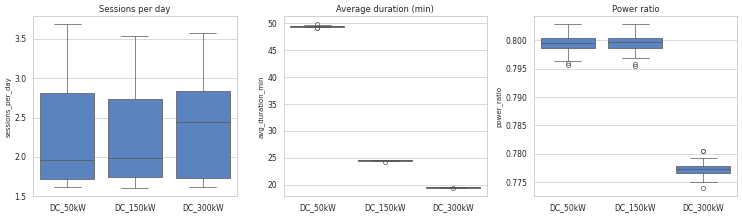

In [6]:
s['half'] = s['start_timestamp'].dt.month % 2           # odd vs even months
years = 2025 - ind['activation_year']
h = s.groupby(['charger_id', 'half'])
half = pd.concat({
    'sessions_per_day': h.size().unstack().div(years, axis=0),
    'avg_duration_min': h['session_duration_minutes'].mean().unstack(),
    'power_ratio'     : h['power_ratio'].mean().unstack(),
    'kwh_per_session' : h['energy_kwh'].mean().unstack(),
    'overlap_rate'    : h['overlap'].mean().unstack(),
}, axis=1)

groups = [ind['charger_type'], ind['n_chargers']]
def remove_group_effect(x):
    return x - x.groupby(groups).transform('mean')

rows = []
for col in ['sessions_per_day', 'avg_duration_min', 'power_ratio', 'kwh_per_session', 'overlap_rate']:
    whole = ind[col]
    r2 = 1 - remove_group_effect(whole).var() / whole.var()
    a, b = remove_group_effect(half[(col, 0)]), remove_group_effect(half[(col, 1)])
    rows.append({'indicator': col, 'explained_by_type_and_size': round(r2, 3), 'odd_vs_even_months_corr': round(a.corr(b), 2)})
reliab = pd.DataFrame(rows).set_index('indicator')
display(reliab)
print('Type x station-size groups:', ind.groupby(['charger_type', 'n_chargers']).ngroups,
      '| smallest group:', ind.groupby(['charger_type', 'n_chargers']).size().min(), 'chargers')

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a_, col, t in zip(ax, ['sessions_per_day', 'avg_duration_min', 'power_ratio'],
                      ['Sessions per day', 'Average duration (min)', 'Power ratio']):
    sns.boxplot(data=ind, x='charger_type', y=col, order=['DC_50kW', 'DC_150kW', 'DC_300kW'], ax=a_, color='#4a7fd1')
    a_.set_title(t); a_.set_xlabel('')
show('01_indicators_by_type')

Charger type and station size explain 97% to 100% of the differences between chargers on every one of the five indicators. After removing those group averages, almost nothing repeats between odd and even months: the correlations are -0.05 (sessions per day), 0.13 (duration, 0.05 (power ratio), 0.17 (kWh per session), and -0.11 (overlap rate). Only kWh per session edges above the noise level of about 0.14. There are 15 groups, and the smallest has just 2 chargers.

**Building the monthly table and the label**  
The model works on charger-months. For each charger and month, the indicators are recalculated from that month's sessions, plus recent history: a 3-month average of sessions, the number of quiet spells in the last 3 months, cumulative energy delivered (a wear measure), and months in service.  
The label is an inactivity event: next month, the charger has a gap of 3 or more days between two session starts. This is a proxy, since the data holds no failure records. I checked its share by year, station size, and rated power to see what the label really captures.

In [7]:
s['month'] = s['start_timestamp'].dt.to_period('M')
s['quiet_event'] = (s['quiet_days'] >= 3).astype(int)

m = s.groupby(['charger_id', 'month'])
panel = pd.DataFrame({
    'sessions'          : m.size(),
    'kwh'               : m['energy_kwh'].sum(),
    'busy_hours'        : m['busy_min'].sum() / 60,
    'avg_duration_min'  : m['session_duration_minutes'].mean(),
    'duration_sd'       : m['session_duration_minutes'].std(),
    'kwh_per_session'   : m['energy_kwh'].mean(),
    'power_ratio'       : m['power_ratio'].mean(),
    'overlap_rate'      : m['overlap'].mean(),
    'longest_quiet_days': m['quiet_days'].max(),
    'quiet_events'      : m['quiet_event'].sum(),
}).reset_index().sort_values(['charger_id', 'month'])

expected = (12 * (2025 - ind['activation_year'])).sum()
print('Charger-months:', len(panel), '| expected from activation years:', expected)

pg = panel.groupby('charger_id')
panel['sessions_3m'] = pg['sessions'].transform(lambda x: x.rolling(3, min_periods=1).mean())
panel['sessions_vs_3m'] = panel['sessions'] / panel['sessions_3m']
panel['quiet_events_3m'] = pg['quiet_events'].transform(lambda x: x.rolling(3, min_periods=1).sum())
panel['cum_kwh'] = pg['kwh'].cumsum()
panel['months_in_service'] = pg.cumcount() + 1
panel = panel.merge(ind[['max_power_kW', 'n_chargers']], left_on='charger_id', right_index=True)

next_events = pg['quiet_events'].shift(-1)
panel['next_quiet_event'] = (next_events > 0).astype(float).where(next_events.notna())

labelled = panel.dropna(subset=['next_quiet_event'])
print(f"Labelled charger-months: {len(labelled):,} | followed by an inactivity event: {labelled['next_quiet_event'].mean():.1%}")
print('By year:', labelled.groupby(labelled['month'].dt.year)['next_quiet_event'].mean().round(3).to_dict())
print('By station size:', labelled.groupby('n_chargers')['next_quiet_event'].mean().round(3).to_dict())
print('By rated power:', labelled.groupby('max_power_kW')['next_quiet_event'].mean().round(3).to_dict())
print('Chargers with at least one event:', labelled.loc[labelled['next_quiet_event'] == 1, 'charger_id'].nunique(), 'of', labelled['charger_id'].nunique())

Charger-months: 4128 | expected from activation years: 4128
Labelled charger-months: 3,929 | followed by an inactivity event: 14.6%
By year: {2022: 0.101, 2023: 0.15, 2024: 0.154}
By station size: {4: 0.004, 5: 0.016, 6: 0.065, 7: 0.133, 8: 0.284}
By rated power: {50: 0.151, 150: 0.156, 300: 0.115}
Chargers with at least one event: 135 of 199


The table has 4,128 charger-months, exactly as expected from the activation years. Of these, 3,929 can be labelled (the last month of each charger has no "next month"), and 14.6% are followed by inactivity. 135 of the 199 chargers have at least one.  
The label is closely tied to station size, not charger conditions. The event rate rises from 0.4% at 4-charger stations to 1.6%, 6.5%, and 13.3% at 6-charger stations, and to 28.4% at 8-charger stations. This is because each station received roughly the same total number of sessions as its size (as found in the utilisation analysis), so chargers at bigger stations get fewer sessions each and are more likely to go quiet for days by chance. Rated power matters much less (15.1% for 50 kW, 15.6% for 150 kW and 11.5% for 300 kW), and the rate rises from 10.1% in 2022 to 15.0% in 2023 and 15.4% in 2024.  
An inactivity even therefore says more about how thinly a charger's traffic is spread than about whether it is faulty. The model is read with that in mind.

**Training the model on earlier months and testing on later ones**  
I trained on months up to December 2023 and tested on 2024 months, so the model is always tested on a future it hasn't seen. XGBoost is trained on 17 features: this month's indicators, recent history, wear (cumulative energy and months in service), rated power, and station size. The model gives each charger-month a risk score between 0 and 1 for an inactivity event next month.

In [8]:
from xgboost import XGBClassifier

FEATURES = ['sessions', 'kwh', 'busy_hours', 'avg_duration_min', 'duration_sd', 'kwh_per_session', 'power_ratio',
            'overlap_rate', 'longest_quiet_days', 'quiet_events', 'sessions_3m', 'sessions_vs_3m', 'quiet_events_3m',
            'cum_kwh', 'months_in_service', 'max_power_kW', 'n_chargers']

data = labelled.copy()
SPLIT = pd.Period('2023-12', 'M')
train = data[data['month'] <= SPLIT]
test  = data[data['month'] > SPLIT]
print(f"train: {len(train):,} charger-months ({train['month'].min()} to {train['month'].max()}), event rate {train['next_quiet_event'].mean():.1%}")
print(f"test : {len(test):,} charger-months ({test['month'].min()} to {test['month'].max()}), event rate {test['next_quiet_event'].mean():.1%}")

model = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                      colsample_bytree=0.8, random_state=42, eval_metric='logloss')
model.fit(train[FEATURES], train['next_quiet_event'])

test = test.assign(risk=model.predict_proba(test[FEATURES])[:, 1])
print(test['risk'].describe().round(3))

train: 1,740 charger-months (2022-01 to 2023-12), event rate 13.6%
test : 2,189 charger-months (2024-01 to 2024-11), event rate 15.4%
count    2189.000
mean        0.143
std         0.143
min         0.001
25%         0.012
50%         0.103
75%         0.238
max         0.821
Name: risk, dtype: float64


The training set has 1,740 charger-months (January 2022 to December 2023, event rate 13.6%), and the test set has 2,189 (January to November 2024, event rate 15.4%). The risk score on the test set has a median of 0.10 and ranges from 0.001 to 0.82, with a quarter of charger-months above 0.24.  
These scores are the model's estimates that a charger goes quiet for 3+ days next month, not that it will fail. 

**How good is the model, and is it better than something simple?**  
The model's score are checked on 2024 data it never saw. It is compared with three simple alternatives: ranking by low recent traffic, ranking by station size alone, and a small XGBoost model that uses only those two. Each is measured by AUC, average precision, and the vent rate among the 10% of charger-months it ranks riskiest (compared with the overall rate, this is the "lift").  
Because station size drives the label so strongly, the model is also checkedwithin each station size, to see whether it can rank chargers that sit at the same kind of station. Finally, predicted risk is compared with the actual event rate by risk decile.

,auc,avg_precision,event_rate_in_top_10pct,lift_top_10pct
model,,,,
Full XGBoost model (17 features),0.728,0.268,0.280,1.818
Baseline: low recent traffic (sessions_3m),0.753,0.278,0.284,1.847
Baseline: station size (n_chargers),0.753,0.267,0.248,1.609
Baseline: XGBoost on station size + traffic only,0.736,0.268,0.248,1.609


Overall test event rate: 15.4%
AUC within each station size:


,station_size,rows,auc
0,4,396,0.176
1,5,330,0.309
2,6,264,0.462
3,7,231,0.462
4,8,968,0.505


Weighted average within-size AUC: 0.406


,predicted,actual
decile,,
1,0.002,0.027
2,0.005,0.005
3,0.013,0.014
4,0.037,0.100
5,0.076,0.128
6,0.130,0.197
7,0.185,0.251
8,0.239,0.283
9,0.304,0.251


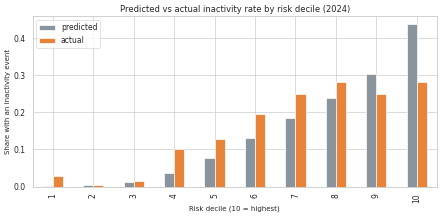

In [9]:
from sklearn.metrics import roc_auc_score, average_precision_score

y = test['next_quiet_event']

def top10_event_rate(score):
    k = int(len(test) * 0.10)
    return y.loc[score.sort_values(ascending=False).index[:k]].mean()

def small_model(cols):
    m = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42, eval_metric='logloss')
    m.fit(train[cols], train['next_quiet_event'])
    return pd.Series(m.predict_proba(test[cols])[:, 1], index=test.index)

scores = {
    'Full XGBoost model (17 features)'                : test['risk'],
    'Baseline: low recent traffic (sessions_3m)'      : -test['sessions_3m'],
    'Baseline: station size (n_chargers)'             : test['n_chargers'] + 1e-6 * np.random.RandomState(0).rand(len(test)),
    'Baseline: XGBoost on station size + traffic only': small_model(['n_chargers', 'sessions_3m']),
}
rows = []
for name, sc in scores.items():
    rows.append({'model': name, 'auc': roc_auc_score(y, sc), 'avg_precision': average_precision_score(y, sc),
                 'event_rate_in_top_10pct': top10_event_rate(sc)})
evaluation = pd.DataFrame(rows).set_index('model')
evaluation['lift_top_10pct'] = evaluation['event_rate_in_top_10pct'] / y.mean()
display(evaluation.round(3))
print(f"Overall test event rate: {y.mean():.1%}")

within = []
for n, grp in test.groupby('n_chargers'):
    if grp['next_quiet_event'].nunique() == 2:
        within.append((n, len(grp), roc_auc_score(grp['next_quiet_event'], grp['risk'])))
within = pd.DataFrame(within, columns=['station_size', 'rows', 'auc'])
print('AUC within each station size:')
display(within.round(3))
print('Weighted average within-size AUC:', round((within['rows'] * within['auc']).sum() / within['rows'].sum(), 3))

test['decile'] = pd.qcut(test['risk'], 10, labels=False) + 1
calibration = test.groupby('decile').agg(predicted=('risk', 'mean'), actual=('next_quiet_event', 'mean')).round(3)
display(calibration)
ax = calibration.plot(kind='bar', figsize=(9, 4.5), color=['#8a949c', '#e8833a'])
ax.set_title('Predicted vs actual inactivity rate by risk decile (2024)')
ax.set_xlabel('Risk decile (10 = highest)'); ax.set_ylabel('Share with an inactivity event')
show('02_risk_calibration')

The full model has an AUC of 0.728 on 2024 data, and its riskiest 10% of charger-months have an event rate of 28.0%, 1.8 times the overall 15.4%. But simple baselines do as well or better. Ranking by low recent traffic alone gives an AUC of 0.753 and a top-10% event rate of 28.4%, and ranking by station size alone also gives an AUC of 0.753. A small model using only station size and traffic scores 0.736.
Within chargers at the same kind of station, the model's ranking is no better than chance (weighted AUC 0.41). In the largest group, the 968 charger-months at 8-charger stations, the AUC is 0.51. The 4-charger and 5-charger groups have very few events, so their values (0.18 and 0.31) are unreliable.
The decile chart shows the scores are overconfident at the top: the highest-risk decile is predicted at 44% but has an actual rate of 28%. The lowest three deciles are reliable, with actual rates between 0.5% and 2.7%. Mid-range deciles are underestimated (for example 3.7% predicted against 10.0% actual in decile 4), partly because inactivity events were more common in 2024 than in training.
The model's real skill is limited to separating chargers that rarely go quiet (small stations, higher traffic) from the rest. It adds nothing beyond traffic level and station size.

**Which feature does the model rely on?**  
Two measures are used. Permutation importance shuffles one feature at a time on the 2024 test data and records how much the AUC fails, which shows how much the model really needs it. Gain importance is XGBoost's own measures of how much each feature improves its splits. A feature with zero negative permutation importance gives the model nothing useful on new data.

,gain_importance,permutation_auc_drop,permutation_sd
sessions_3m,0.1197,0.1070,0.0136
n_chargers,0.3819,0.0240,0.0064
busy_hours,0.0323,0.0036,0.0024
sessions_vs_3m,0.0330,0.0029,0.0016
power_ratio,0.0353,0.0026,0.0026
duration_sd,0.0342,0.0024,0.0026
sessions,0.0458,0.0020,0.0039
avg_duration_min,0.0305,0.0019,0.0021
max_power_kW,0.0000,0.0000,0.0000
overlap_rate,0.0375,-0.0003,0.0045


Features with zero or negative permutation importance: 9 of 17


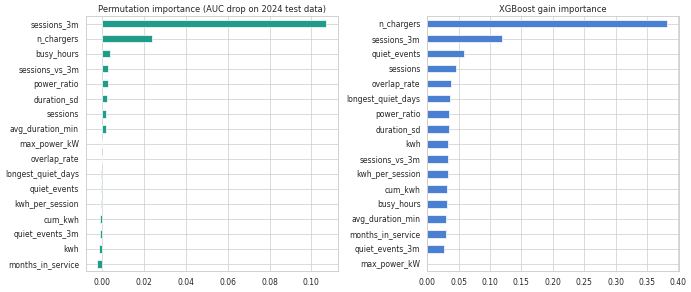

In [10]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(model, test[FEATURES], y, scoring='roc_auc', n_repeats=20, random_state=42)
importance = pd.DataFrame({'gain_importance': model.feature_importances_,
                           'permutation_auc_drop': perm.importances_mean,
                           'permutation_sd': perm.importances_std},
                          index=FEATURES).sort_values('permutation_auc_drop', ascending=False)
display(importance.round(4))
print('Features with zero or negative permutation importance:', (importance['permutation_auc_drop'] <= 0).sum(), 'of', len(importance))

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
importance['permutation_auc_drop'].iloc[::-1].plot(kind='barh', ax=ax[0], color='#1f9d8a')
ax[0].set_title('Permutation importance (AUC drop on 2024 test data)')
importance['gain_importance'].sort_values().plot(kind='barh', ax=ax[1], color='#4a7fd1')
ax[1].set_title('XGBoost gain importance')
show('03_feature_importance')

The model relies on two features. Recent traffic (sessions over the last 3 months) is by far the most important: shuffling it cuts the AUC by 0.107. Station size comes next, at 0.024. Every other feature changes the AUC by 0.004 or less, and nine of the 17 have zero or negative importance. The remaining positive values (busy hours, sessions against the 3-month average, power ratio, duration variability, sessions and average duration) are all within about 2 standard deviations of zero, so they cannot be told apart from noise.
The two measures agree on the top two features but order them differently. Gain importance puts station size first (0.38) and traffic second (0.12), and spreads the rest across many features that add nothing on new data.
The wear measures (cumulative energy and months in service) have no predictive value for inactivity (-0.001 and -0.002). Power ratio and the other session-shape indicators carry almost no signal either, which matches the noise check made prior.

**Ranking chargers for maintenance**  
Each charger is scores using its December 2024 data, which gives the model's inactivity risk for January 2024. Because the risk score mostly reflects station size and traffic, it is combines with wear, which measures how hard a charger has worked: thr average of its rank by total sessions (connector cycle) and by tital energy delivered. The priority score is a weighted average of risk rank and wear rank, wuth the weights set in W_RISK and W_WEAR so they can be changed.  
Chargers are placed in tiers: Tier 1 is the top 10% by priority score, Tier 2 the next 20%, and Tier 3 the rest. three screening flags mark chargers worth a look whatever their tier: an unusually long quiet spell (gap ratio above 1.5), falling sessions (recent rate below 85% of the previous year's) and falling delivered power (down more than 1%). Flagged chargers get an inspection action. 

Scoring month: 2024-12 | chargers: 199
{'Tier 3': 139, 'Tier 2': 40, 'Tier 1': 20} | flagged for inspection: 14
Correlation between risk rank and wear rank: -0.45


,chargers,median_sessions,share_of_sessions
tier,,,
Tier 1,20,1727.0,0.116
Tier 2,40,1931.0,0.301
Tier 3,139,995.0,0.583


,station_id,charger_type,n_chargers,activation_year,sessions,risk,wear_pct,priority_score,tier,action
charger_id,,,,,,,,,,
STN_004_CH_08,STN_004,DC_300kW,8,2022,1901,0.52,0.83,0.91,Tier 1,Schedule wear service
STN_005_CH_01,STN_005,DC_300kW,8,2022,1859,0.32,0.81,0.85,Tier 1,Inspect now: delivered power falling
STN_005_CH_08,STN_005,DC_150kW,8,2022,1935,0.28,0.77,0.81,Tier 1,Inspect now: sessions falling
STN_016_CH_03,STN_016,DC_300kW,6,2023,1683,0.27,0.79,0.80,Tier 1,Schedule wear service
STN_005_CH_05,STN_005,DC_150kW,8,2022,1881,0.27,0.75,0.78,Tier 1,Schedule wear service
STN_004_CH_06,STN_004,DC_150kW,8,2022,1963,0.25,0.79,0.78,Tier 1,Schedule wear service
STN_015_CH_05,STN_015,DC_150kW,7,2023,1419,0.31,0.68,0.78,Tier 1,Schedule wear service
STN_013_CH_04,STN_013,DC_300kW,8,2023,1266,0.34,0.66,0.78,Tier 1,Schedule wear service
STN_016_CH_04,STN_016,DC_50kW,6,2023,1670,0.40,0.62,0.77,Tier 1,Schedule wear service


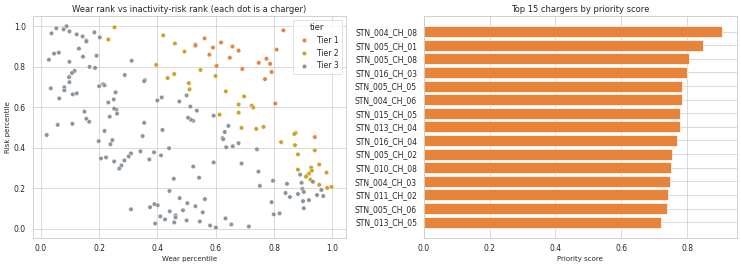

,station_id,charger_type,rank,tier,flags
charger_id,,,,,
STN_005_CH_01,STN_005,DC_300kW,2,Tier 1,delivered power falling
STN_005_CH_08,STN_005,DC_150kW,3,Tier 1,sessions falling
STN_015_CH_04,STN_015,DC_50kW,16,Tier 1,delivered power falling
STN_004_CH_02,STN_004,DC_300kW,18,Tier 1,unusually long quiet spell; sessions falling
STN_004_CH_05,STN_004,DC_50kW,28,Tier 2,unusually long quiet spell
STN_020_CH_03,STN_020,DC_50kW,41,Tier 2,sessions falling
STN_013_CH_01,STN_013,DC_150kW,44,Tier 2,delivered power falling
STN_015_CH_07,STN_015,DC_150kW,51,Tier 2,delivered power falling
STN_002_CH_04,STN_002,DC_300kW,57,Tier 2,delivered power falling


In [11]:
latest = panel[panel['month'] == panel['month'].max()].set_index('charger_id')
print('Scoring month:', latest['month'].iloc[0], '| chargers:', len(latest))

pr = ind[['station_id', 'region', 'charger_type', 'n_chargers', 'activation_year', 'sessions', 'kwh_total',
          'gap_ratio', 'sessions_trend', 'power_ratio_change']].copy()
pr['risk'] = model.predict_proba(latest.loc[pr.index, FEATURES])[:, 1]
pr['risk_pct'] = pr['risk'].rank(pct=True)
pr['wear_pct'] = pd.concat([pr['sessions'].rank(pct=True), pr['kwh_total'].rank(pct=True)], axis=1).mean(axis=1)

W_RISK, W_WEAR = 0.5, 0.5
pr['priority_score'] = W_RISK * pr['risk_pct'] + W_WEAR * pr['wear_pct']
pr['rank'] = pr['priority_score'].rank(ascending=False, method='first').astype(int)
pr = pr.sort_values('rank')

def flags(row):
    f = []
    if row['gap_ratio'] > 1.5: f.append('unusually long quiet spell')
    if row['sessions_trend'] < 0.85: f.append('sessions falling')
    if row['power_ratio_change'] < -0.01: f.append('delivered power falling')
    return '; '.join(f)
pr['flags'] = pr.apply(flags, axis=1)

n = len(pr)
pr['tier'] = np.where(pr['rank'] <= round(0.10 * n), 'Tier 1', np.where(pr['rank'] <= round(0.30 * n), 'Tier 2', 'Tier 3'))
pr['action'] = np.select(
    [pr['flags'] != '', pr['tier'] == 'Tier 1', pr['tier'] == 'Tier 2'],
    ['Inspect now: ' + pr['flags'], 'Schedule wear service', 'Next service cycle'], default='Routine')

print(pr['tier'].value_counts().to_dict(), '| flagged for inspection:', (pr['flags'] != '').sum())
print('Correlation between risk rank and wear rank:', round(pr[['risk_pct', 'wear_pct']].corr().iloc[0, 1], 2))
tier_sum = pr.groupby('tier').agg(chargers=('rank', 'size'), median_sessions=('sessions', 'median'), share_of_sessions=('sessions', 'sum'))
tier_sum['share_of_sessions'] = (tier_sum['share_of_sessions'] / pr['sessions'].sum()).round(3)
display(tier_sum)
display(pr.head(15)[['station_id', 'charger_type', 'n_chargers', 'activation_year', 'sessions',
                     'risk', 'wear_pct', 'priority_score', 'tier', 'action']].round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(data=pr, x='wear_pct', y='risk_pct', hue='tier', hue_order=['Tier 1', 'Tier 2', 'Tier 3'],
                palette=['#e8833a', '#c9a227', '#8a949c'], ax=ax[0], s=40)
ax[0].set_title('Wear rank vs inactivity-risk rank (each dot is a charger)')
ax[0].set_xlabel('Wear percentile'); ax[0].set_ylabel('Risk percentile')
top = pr.head(15).iloc[::-1]
ax[1].barh(top.index, top['priority_score'], color='#e8833a')
ax[1].set_title('Top 15 chargers by priority score'); ax[1].set_xlabel('Priority score')
show('04_priority_list')

pr.loc[pr['flags'] != '', ['station_id', 'charger_type', 'rank', 'tier', 'flags']]

The list has 20 chargers in Tier 1, 40 in Tier 2 and 139 in Tier 3. Risk rank and wear rank are negatively related (-0.45), because the chargers that work hardest are less likely to go quiet. A charger therefore reaches the top only by being high on both, which means heavily used chargers at larger stations.
Tier 1 is made up of chargers from the 2022 and 2023 sites (10 each), and 14 of the 20 are at 8-charger stations. They are used more than the typical charger (median 1,727 sessions against 1,258 overall). Tier 2 has a median of 1,931 sessions, and Tiers 1 and 2 together are 30% of chargers but handled 42% of all sessions, so servicing them first covers the busiest equipment.
14 chargers are flagged for inspection: 3 with an unusually long quiet spell (STN_004_CH_02 in Tier 1, STN_004_CH_05 in Tier 2 and STN_025_CH_02 in Tier 3), 6 with falling sessions and 7 with falling delivered power (two chargers have two flags). They are inspected whatever their tier. The flag thresholds are screening rules, not tested limits, and the noise check made earlier showed charger differences do not repeat from month to month, so some flags will be chance. They are reasons to look, not diagnoses.

**Preventive maintenance recommendations**  
The recommendations are limited to what the evidence supports. The model's inactivity risk is not a failure forecast, so the main actions rely on wear and on collecting better data.
1. **Treat the risk model as a screening aid, not a failure predictor.** It matches simple traffic and station-size rules and cannot rank chargers within a station size. Do not schedule repairs from its scores alone.
2. **Start recording real failures.** Log fault and status codes, downtime start and end, work orders and parts replaced for every charger. With that data this pipeline can be retrained to predict outages in the next 30 days, using the monthly indicators and wear measures already built.
3. **Service by wear, not by calendar.** Chargers differ a lot in work done: the busiest has delivered about 15 times the energy of the least busy (292,098 kWh against 19,646), and chargers from 2022 average 2,825 sessions each against 1,550 for 2023 and 836 for 2024. A fixed calendar schedule would service a heavily used charger and a lightly used one at the same interval. Work through Tier 1 (20 chargers), then Tier 2 (40).
4. **Inspect the 14 flagged chargers now,** starting with the three that have unusually long quiet spells (STN_004_CH_02, STN_004_CH_05, STN_025_CH_02). Confirm whether the cause is hardware, charger allocation or something else.
5. **Fix charger allocation and logging.** 8.3% of sessions start before the previous session on the same charger has ended. Until this is fixed, health monitoring cannot separate a real availability problem from a logging one.
6. **Monitor monthly with alert limits.** Starting points, set just beyond the largest deviations seen in this data and to be tuned once fault data exists: gap ratio above 2 (highest seen 1.9), sessions trend below 0.70 (lowest 0.75), delivered power down more than 3% (range -1.8% to +1.6%), and a quiet spell over 10 days (longest 8.2).
7. **Check whether the lower power ratio on 300 kW chargers is by design.** They deliver 77.7% of rated power, against 80.0% for the others. This may be normal, but it is the only consistent difference between types in delivered power.

**Saving the outputs**  
The health indicators, noise check, model evaluation, feature importance, risk scores and priority list are saved as CSVs so they can be used in the dashboard.

In [12]:
risk_scores = test[['charger_id', 'month', 'next_quiet_event', 'risk']].reset_index(drop=True).assign(month=lambda d: d['month'].astype(str))
files = {
    'charger_health_indicators.csv' : ind.reset_index(),
    'indicator_reliability.csv'     : reliab.reset_index(),
    'model_evaluation.csv'          : evaluation.reset_index(),
    'risk_calibration_by_decile.csv': calibration.reset_index(),
    'feature_importance.csv'        : importance.reset_index().rename(columns={'index': 'feature'}),
    'risk_scores_2024.csv'          : risk_scores,
    'maintenance_priority_list.csv' : pr.reset_index(),
}
for name, df in files.items():
    df.to_csv(f'{OUT}/{name}', index=False)
print(sorted(f for f in os.listdir(OUT) if f.endswith('.csv')))

['charger_health_indicators.csv', 'feature_importance.csv', 'indicator_reliability.csv', 'maintenance_priority_list.csv', 'model_evaluation.csv', 'risk_calibration_by_decile.csv', 'risk_scores_2024.csv']
